# Итоговое сравнение алгоритмов лабораторных 1–5

**Студент:** Чибугаев Илья Алексеевич, вариант 22.

Notebook объединяет результаты пяти работ на неизменных train/test-разбиениях. Сравнение проводится отдельно для классификации и регрессии, поскольку их метрики и шкалы несопоставимы. Основной практический вывод делается по улучшенным моделям; бейзлайны сохранены для оценки эффекта настройки.


## 1. Загрузка и контроль полноты

Ожидаются пять файлов, в каждом — четыре конфигурации для двух задач (восемь строк). Отсутствие файла или строки останавливает анализ.

In [1]:
# Читаем результаты всех лабораторных и проверяем полноту перед сравнением.
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
plt.style.use("seaborn-v0_8-whitegrid")
paths = sorted((ROOT / "results").glob("lab??_results.csv"))
assert len(paths) == 5, f"Ожидалось 5 файлов, найдено: {len(paths)}"
results = pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)
assert len(results) == 40, f"Ожидалось 40 строк, получено: {len(results)}"
assert set(results["lab"]) == {1, 2, 3, 4, 5}
assert not results.duplicated(["lab", "task", "implementation", "stage"]).any()
results.to_csv(ROOT / "results" / "all_results.csv", index=False)
print(f"Загружено {len(results)} результатов из {len(paths)} лабораторных")
display(results.drop(columns=["params"]))

Загружено 40 результатов из 5 лабораторных


,lab,algorithm,task,implementation,stage,accuracy,f1,roc_auc,rmse,mae,r2,fit_seconds
0,1,KNN,classification,sklearn,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,2.1923e-03
1,1,KNN,classification,sklearn,improved,0.8592,0.7500,0.9361,NaN,NaN,NaN,1.5550e+00
2,1,KNN,classification,from_scratch,baseline,0.8169,0.6486,0.8683,NaN,NaN,NaN,4.5125e-05
3,1,KNN,classification,from_scratch,improved,0.8592,0.7500,0.9361,NaN,NaN,NaN,3.2500e-05
4,1,KNN,regression,sklearn,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,1.6189e-03
5,1,KNN,regression,sklearn,improved,NaN,NaN,NaN,7.7874,5.7290,0.7969,5.7185e-02
6,1,KNN,regression,from_scratch,baseline,NaN,NaN,NaN,8.8069,7.0053,0.7403,1.2709e-05
7,1,KNN,regression,from_scratch,improved,NaN,NaN,NaN,7.7874,5.7290,0.7969,9.5000e-06
8,2,Логистическая / линейная регрессия,classification,sklearn,baseline,0.7746,0.5294,0.8313,NaN,NaN,NaN,3.6814e-03
9,2,Логистическая / линейная регрессия,classification,sklearn,improved,0.8028,0.6316,0.8696,NaN,NaN,NaN,1.3052e+00


## 2. Эффект улучшенного бейзлайна

Сводная таблица содержит основную метрику каждой задачи до и после настройки. Для RMSE меньшее значение лучше, для ROC-AUC — большее.

In [2]:
# Строим сводку основной метрики по алгоритму, реализации и этапу настройки.
summary_rows = []
for (lab, algorithm, task, implementation), group in results.groupby(["lab", "algorithm", "task", "implementation"]):
    indexed = group.set_index("stage")
    metric = "roc_auc" if task == "classification" else "rmse"
    summary_rows.append({
        "lab": lab, "algorithm": algorithm, "task": task, "implementation": implementation,
        "metric": metric, "baseline": indexed.loc["baseline", metric],
        "improved": indexed.loc["improved", metric],
        "change": indexed.loc["improved", metric] - indexed.loc["baseline", metric],
    })
summary = pd.DataFrame(summary_rows).sort_values(["task", "implementation", "lab"])
summary.to_csv(ROOT / "results" / "summary_metrics.csv", index=False)
display(summary)

,lab,algorithm,task,implementation,metric,baseline,improved,change
0,1,KNN,classification,from_scratch,roc_auc,0.8683,0.9361,0.0678
4,2,Логистическая / линейная регрессия,classification,from_scratch,roc_auc,0.6730,0.8704,0.1974
8,3,Решающее дерево,classification,from_scratch,roc_auc,0.8765,0.9270,0.0504
12,4,Случайный лес,classification,from_scratch,roc_auc,0.9983,0.9957,-0.0026
16,5,Градиентный бустинг,classification,from_scratch,roc_auc,0.9904,0.9952,0.0048
1,1,KNN,classification,sklearn,roc_auc,0.8683,0.9361,0.0678
5,2,Логистическая / линейная регрессия,classification,sklearn,roc_auc,0.8313,0.8696,0.0383
9,3,Решающее дерево,classification,sklearn,roc_auc,0.8874,0.9335,0.0461
13,4,Случайный лес,classification,sklearn,roc_auc,0.9948,0.9965,0.0017
17,5,Градиентный бустинг,classification,sklearn,roc_auc,0.9957,0.9974,0.0017


## 3. Визуальное сравнение

На графиках показаны улучшенные модели. Для классификации дополнительно приведён F1 по классу `bad`, для регрессии — MAE в МПа, чтобы выбор не опирался на одну метрику.

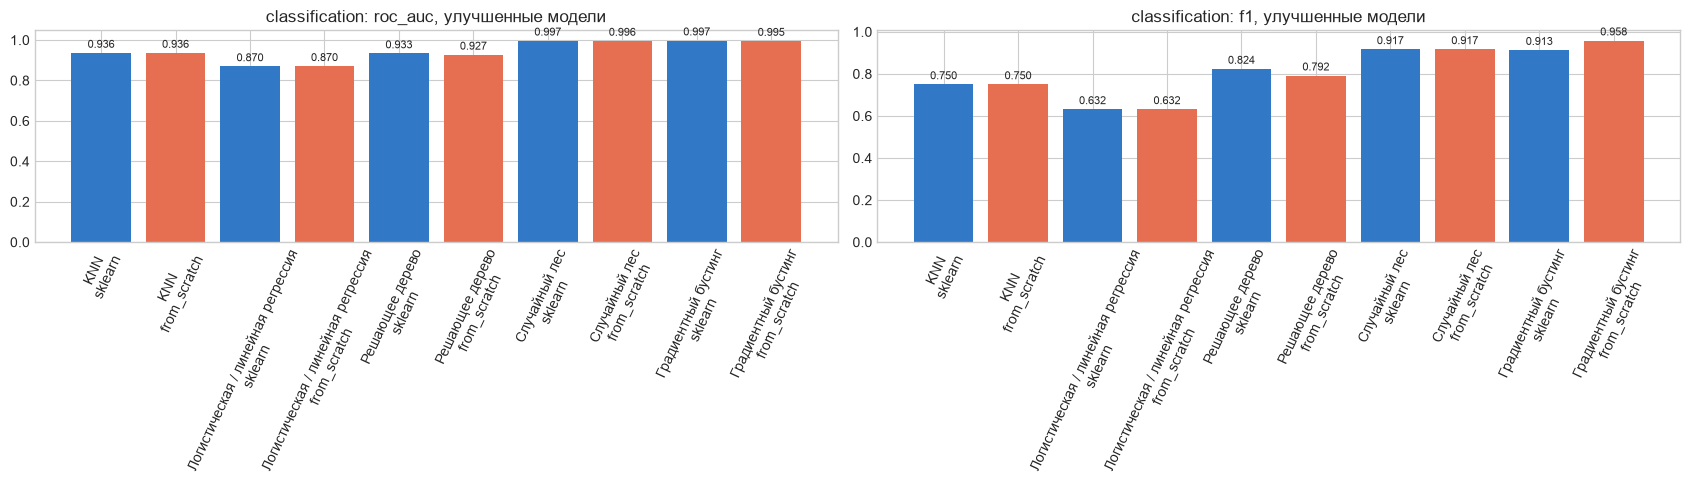

Сохранено: results/comparison_classification.png


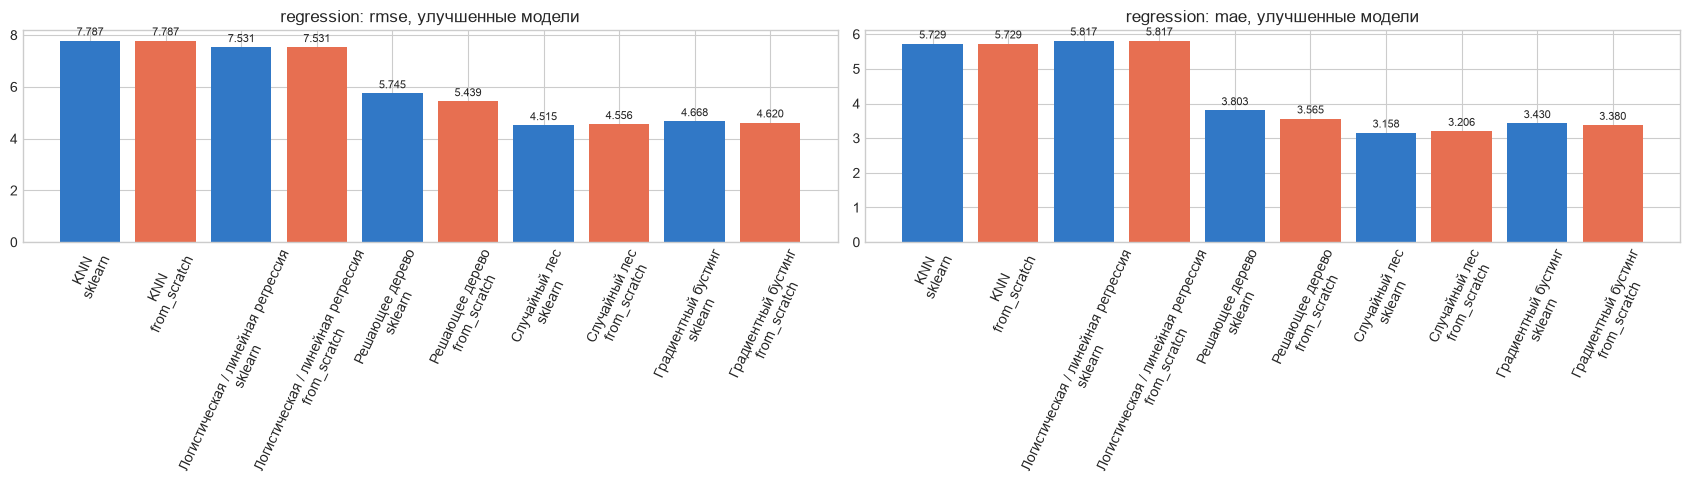

Сохранено: results/comparison_regression.png


In [3]:
# Строим отдельные графики для несопоставимых задач и сохраняем их в results.
for task in ("classification", "regression"):
    subset = results[(results["task"] == task) & (results["stage"] == "improved")].copy()
    subset["model"] = subset["algorithm"] + "\n" + subset["implementation"]
    metrics = ["roc_auc", "f1"] if task == "classification" else ["rmse", "mae"]
    fig, axes = plt.subplots(1, 2, figsize=(17, 5))
    for axis, metric in zip(axes, metrics):
        colors = ["#3178c6" if value == "sklearn" else "#e76f51" for value in subset["implementation"]]
        axis.bar(subset["model"], subset[metric], color=colors)
        axis.set_title(f"{task}: {metric}, улучшенные модели")
        axis.tick_params(axis="x", rotation=65)
        axis.bar_label(axis.containers[0], fmt="%.3f", padding=2, fontsize=8)
    plt.tight_layout()
    figure_path = ROOT / "results" / f"comparison_{task}.png"
    plt.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Сохранено: {figure_path.relative_to(ROOT)}")

## 4. Итоговые выводы

Лучшие конфигурации определяются по фактической основной метрике. Разница реализаций не является ошибкой: у sklearn и локальных алгоритмов могут различаться критерии остановки, детализация оптимизации и число деревьев (для чистого Python явно ограничено).

In [4]:
# Выбираем лидеров по основной метрике и формируем текстовое заключение из рассчитанных значений.
conclusions = []
for task in ("classification", "regression"):
    metric = "roc_auc" if task == "classification" else "rmse"
    ascending = metric == "rmse"
    improved = results[(results["task"] == task) & (results["stage"] == "improved")].sort_values(metric, ascending=ascending)
    best = improved.iloc[0]
    best_sklearn = improved[improved["implementation"] == "sklearn"].iloc[0]
    best_custom = improved[improved["implementation"] == "from_scratch"].iloc[0]
    conclusions.extend([
        f"### {task}",
        f"- Общий лидер по {metric}: **{best['algorithm']} ({best['implementation']})**, значение **{best[metric]:.4f}**.",
        f"- Лучший sklearn: **{best_sklearn['algorithm']}**, {metric} = **{best_sklearn[metric]:.4f}**.",
        f"- Лучшая собственная реализация: **{best_custom['algorithm']}**, {metric} = **{best_custom[metric]:.4f}**.",
    ])
conclusions.extend([
    "### Что учитывать при выборе",
    "Помимо отложенной метрики важны устойчивость CV, стоимость обучения и цена ошибки. "
    "Один train/test-сплит не доказывает статистическую значимость небольших отличий.",
])
display(Markdown("\n".join(conclusions)))

### classification
- Общий лидер по roc_auc: **Градиентный бустинг (sklearn)**, значение **0.9974**.
- Лучший sklearn: **Градиентный бустинг**, roc_auc = **0.9974**.
- Лучшая собственная реализация: **Случайный лес**, roc_auc = **0.9957**.
### regression
- Общий лидер по rmse: **Случайный лес (sklearn)**, значение **4.5147**.
- Лучший sklearn: **Случайный лес**, rmse = **4.5147**.
- Лучшая собственная реализация: **Случайный лес**, rmse = **4.5563**.
### Что учитывать при выборе
Помимо отложенной метрики важны устойчивость CV, стоимость обучения и цена ошибки. Один train/test-сплит не доказывает статистическую значимость небольших отличий.